In [15]:
# LAB ASSIGNMENT 7: DEEP LEARNING GRID SEARCH
# COURSE: AI IN HEALTHCARE (CSET343)
# DATASET: PIMA INDIANS DIABETES

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.optimizers import Adam

In [16]:
# TASK 1: DATA ACQUISITION AND LOADING

url = (
    "https://raw.githubusercontent.com/jbrownlee/Datasets/"
    "master/pima-indians-diabetes.data.csv"
)

columns = [
    "Pregnancies",
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
    "DiabetesPedigreeFunction",
    "Age",
    "Outcome"
]

df = pd.read_csv(url, header=None, names=columns)

print("=" * 60)
print("TASK 1: DATA ACQUISITION AND EXPLORATION")
print("=" * 60)

print("\nFirst 5 rows:")
print(df.head())

print("\nRandom 5 rows:")
print(df.sample(5, random_state=42))

print("\nDataset shape:")
print(df.shape)

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
print(df.describe())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nClass distribution:")
print(df["Outcome"].value_counts())

print("\nClass distribution in percentage:")
print((df["Outcome"].value_counts(normalize=True) * 100).round(2))

TASK 1: DATA ACQUISITION AND EXPLORATION

First 5 rows:
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  

Random 5 rows:
     Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
668            6       98             58             33      190  34.0   
324            2      112             75             32        0  35.7   
624      

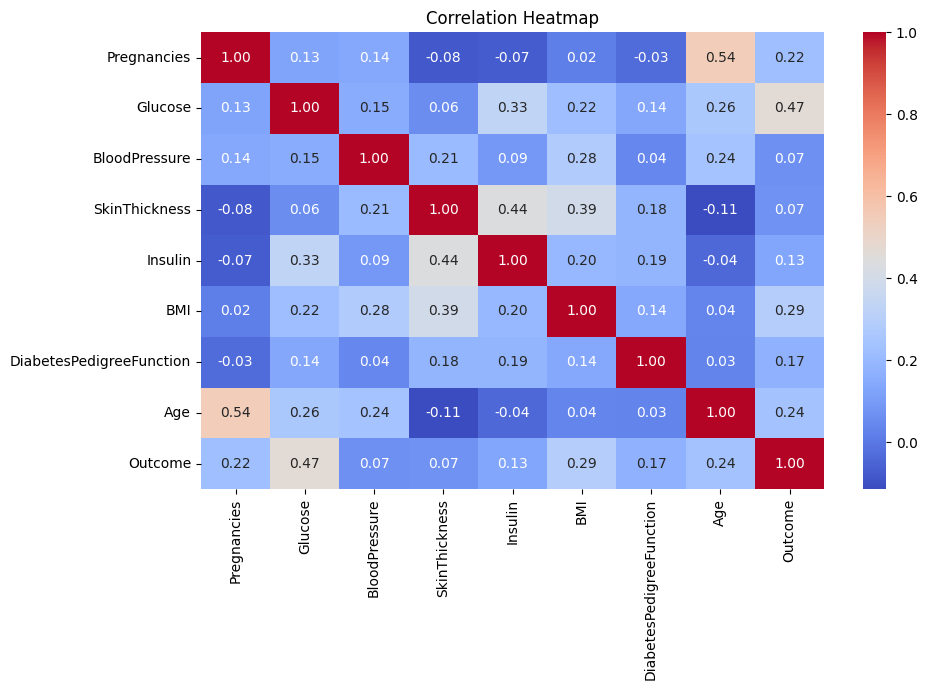

In [17]:
# VISUALIZATIONS
# Correlation heatmap
plt.figure(figsize=(10, 7))
sns.heatmap(
    df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

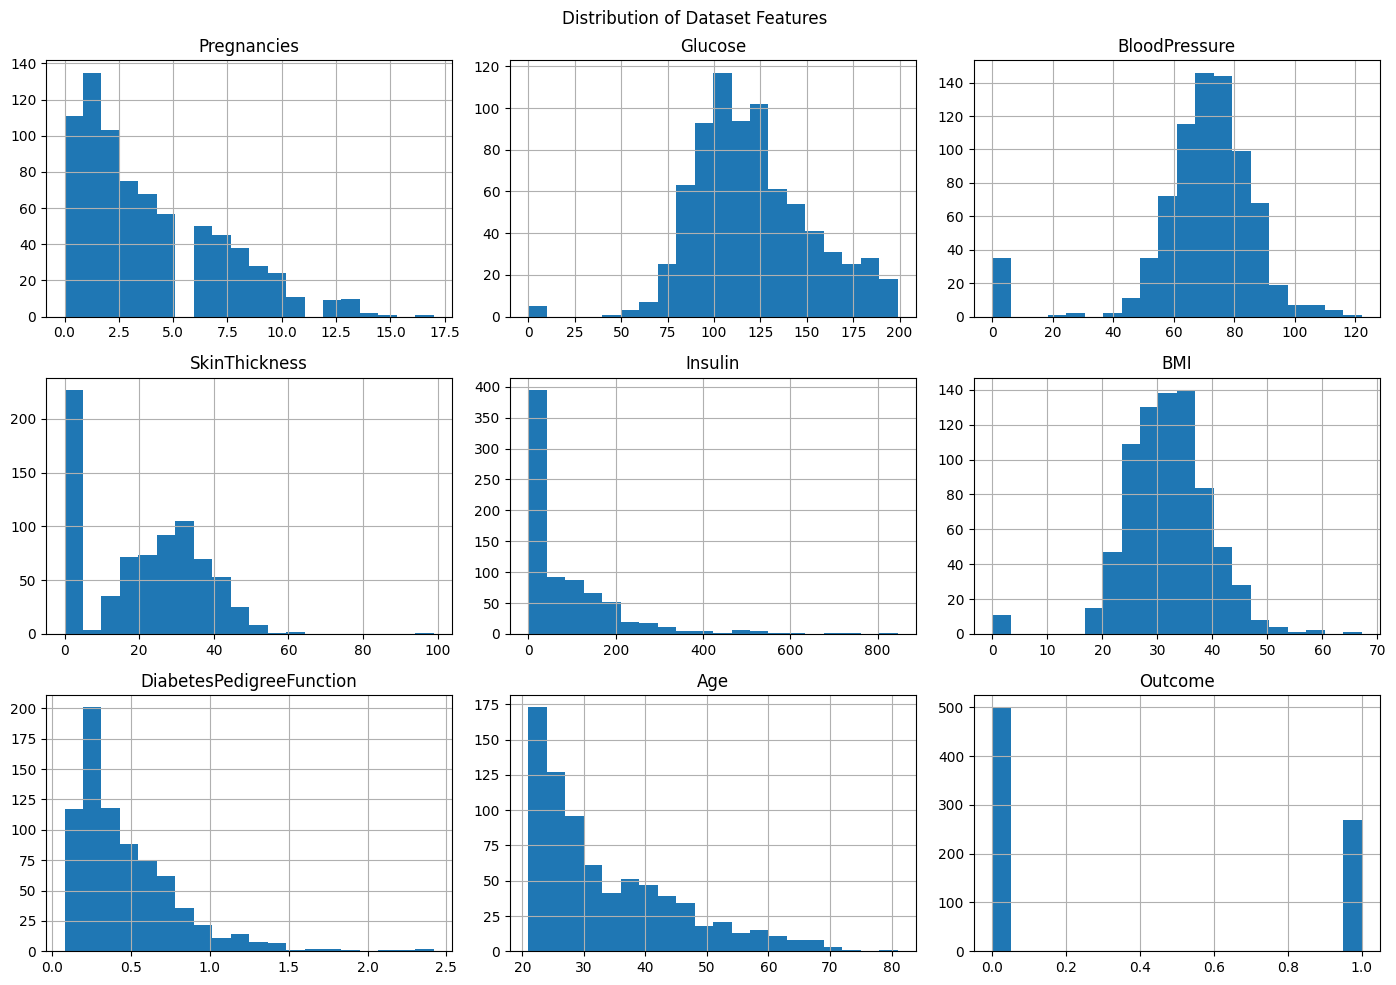

In [18]:
# Feature distributions
df.hist(figsize=(14, 10), bins=20)
plt.suptitle("Distribution of Dataset Features")
plt.tight_layout()
plt.show()

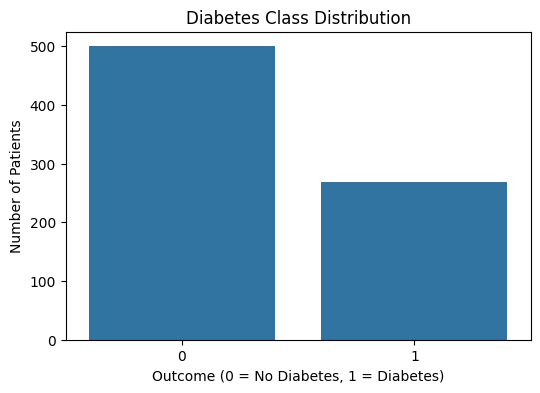

In [19]:
# Class distribution
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Outcome")
plt.title("Diabetes Class Distribution")
plt.xlabel("Outcome (0 = No Diabetes, 1 = Diabetes)")
plt.ylabel("Number of Patients")
plt.show()

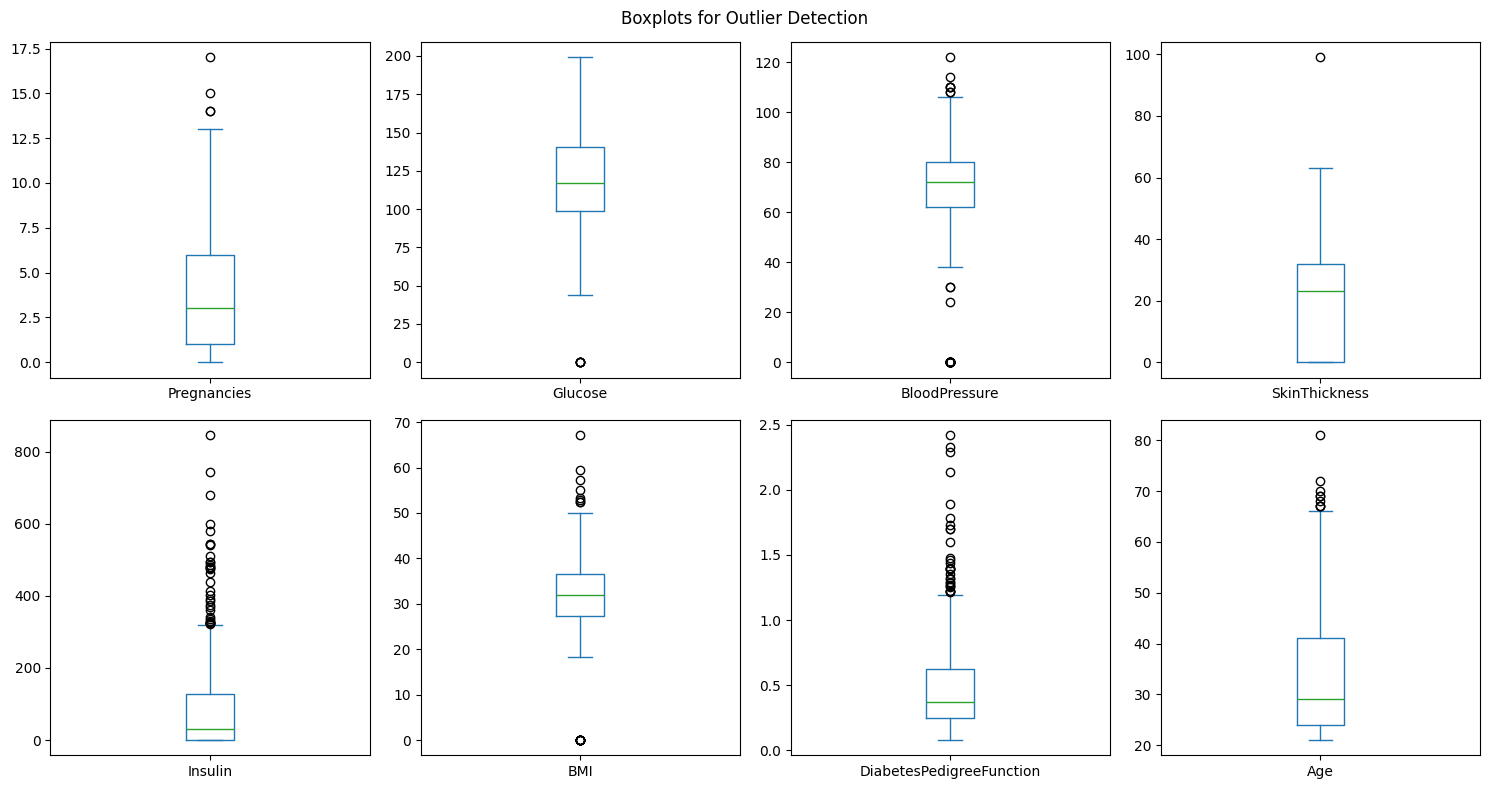

In [20]:
# Boxplots for detecting potential outliers
df.drop(columns=["Outcome"]).plot(
    kind="box",
    subplots=True,
    layout=(2, 4),
    figsize=(15, 8),
    sharex=False,
    sharey=False
)
plt.suptitle("Boxplots for Outlier Detection")
plt.tight_layout()
plt.show()

In [22]:
# TASK 2: DATA PREPROCESSING

print("TASK 2: DATA PREPROCESSING")

X = df.drop(columns=["Outcome"]).copy()
y = df["Outcome"].astype(int)


zero_columns = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

X[zero_columns] = X[zero_columns].replace(0, np.nan)

print("\nMissing values after checking invalid zeros:")
print(X.isnull().sum())

# Split the data before fitting preprocessing transformations.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Handle missing values using training-set medians.
imputer = SimpleImputer(strategy="median")

X_train = imputer.fit_transform(X_train)
X_test = imputer.transform(X_test)

# Standardize numerical features.
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("\nTraining data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("\nPreprocessing completed successfully!")

TASK 2: DATA PREPROCESSING

Missing values after checking invalid zeros:
Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
dtype: int64

Training data shape: (614, 8)
Testing data shape: (154, 8)

Preprocessing completed successfully!


In [9]:
# TASK 3: DEEP LEARNING GRID SEARCH

# Create the neural network classifier.
classifier = DiabetesClassifier()

param_grid = [
    {"batch_size": [16, 32]},

    {"epochs": [30, 50]},

    {"learning_rate": [0.001, 0.01]},

    {"init_mode": ["glorot_uniform", "he_normal"]},

    {"activation": ["relu", "tanh"]},

    {"dropout_rate": [0.2, 0.3]},

    {"neurons": [16, 32]}
]


# GridSearchCV evaluates configurations using 3-fold CV.

grid = GridSearchCV(
    estimator=classifier,
    param_grid=param_grid,
    cv=3,
    scoring="accuracy",
    n_jobs=1,
    verbose=1,
    error_score="raise"
)

print("\nStarting Grid Search...")
print("Please wait. Training may take several minutes.")

grid.fit(X_train, y_train)


Starting Grid Search...
Please wait. Training may take several minutes.
Fitting 3 folds for each of 14 candidates, totalling 42 fits


GridSearchCV(cv=3, error_score='raise', estimator=DiabetesClassifier(),
             n_jobs=1,
             param_grid=[{'batch_size': [16, 32]}, {'epochs': [30, 50]},
                         {'learning_rate': [0.001, 0.01]},
                         {'init_mode': ['glorot_uniform', 'he_normal']},
                         {'activation': ['relu', 'tanh']},
                         {'dropout_rate': [0.2, 0.3]}, {'neurons': [16, 32]}],
             scoring='accuracy', verbose=1)

In [23]:
# DISPLAY GRID SEARCH RESULTS

print("GRID SEARCH RESULTS")

print("\nBest Cross-Validation Accuracy:")
print(round(grid.best_score_, 4))

print("\nBest Hyperparameters:")
print(grid.best_params_)

results = pd.DataFrame(grid.cv_results_)

results = results.sort_values(
    by="mean_test_score",
    ascending=False
)

print("\nAll Grid Search Results:")

print(
    results[
        ["params", "mean_test_score", "std_test_score"]
    ].to_string(index=False)
)

GRID SEARCH RESULTS

Best Cross-Validation Accuracy:
0.7899

Best Hyperparameters:
{'neurons': 32}

All Grid Search Results:
                         params  mean_test_score  std_test_score
                {'neurons': 32}         0.789917        0.010241
         {'activation': 'tanh'}         0.785039        0.011551
                 {'epochs': 50}         0.775259        0.007540
             {'batch_size': 16}         0.772023        0.015623
             {'batch_size': 32}         0.770381        0.011522
                 {'epochs': 30}         0.770381        0.011522
                {'neurons': 16}         0.770381        0.011522
       {'learning_rate': 0.001}         0.770381        0.011522
         {'activation': 'relu'}         0.770381        0.011522
{'init_mode': 'glorot_uniform'}         0.770381        0.011522
          {'dropout_rate': 0.2}         0.770381        0.011522
        {'learning_rate': 0.01}         0.765503        0.015504
     {'init_mode': 'he_normal'

In [24]:
# FINAL MODEL EVALUATION

print("FINAL MODEL EVALUATION")

best_model = grid.best_estimator_

y_pred = best_model.predict(X_test)

test_accuracy = accuracy_score(y_test, y_pred)

print("\nTest Accuracy:")
print(round(test_accuracy, 4))

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["No Diabetes", "Diabetes"],
        zero_division=0
    )
)

FINAL MODEL EVALUATION

Test Accuracy:
0.7013

Classification Report:
              precision    recall  f1-score   support

 No Diabetes       0.75      0.80      0.78       100
    Diabetes       0.58      0.52      0.55        54

    accuracy                           0.70       154
   macro avg       0.67      0.66      0.66       154
weighted avg       0.69      0.70      0.70       154



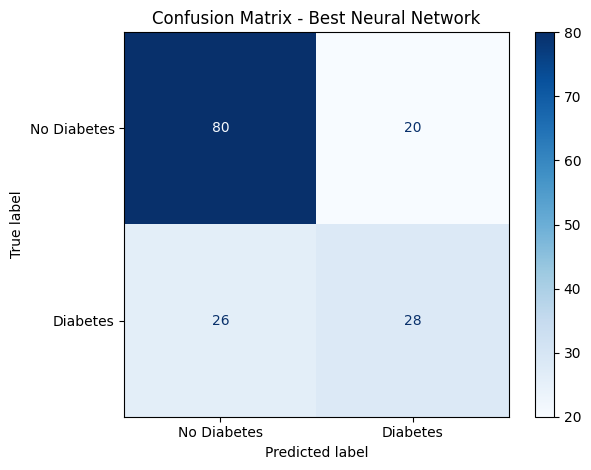

In [12]:
# CONFUSION MATRIX

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["No Diabetes", "Diabetes"],
    cmap="Blues"
)

plt.title("Confusion Matrix - Best Neural Network")
plt.tight_layout()
plt.show()

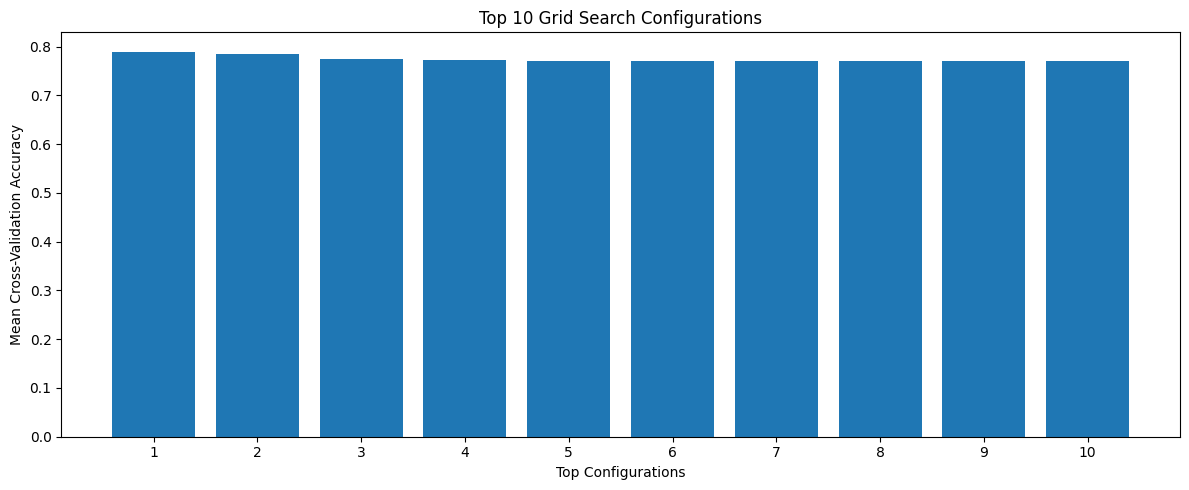

In [13]:
# GRID SEARCH GRAPH

top_results = results.head(10).copy()

plt.figure(figsize=(12, 5))

plt.bar(
    range(1, len(top_results) + 1),
    top_results["mean_test_score"]
)

plt.xlabel("Top Configurations")
plt.ylabel("Mean Cross-Validation Accuracy")
plt.title("Top 10 Grid Search Configurations")
plt.xticks(range(1, len(top_results) + 1))
plt.tight_layout()
plt.show()

In [25]:
# FINAL SUMMARY

print("ASSIGNMENT COMPLETED SUCCESSFULLY!")

print("Dataset records:", len(df))
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Best CV accuracy:", round(grid.best_score_, 4))
print("Test accuracy:", round(test_accuracy, 4))
print("Best parameters:", grid.best_params_)


ASSIGNMENT COMPLETED SUCCESSFULLY!
Dataset records: 768
Training samples: 614
Testing samples: 154
Best CV accuracy: 0.7899
Test accuracy: 0.7013
Best parameters: {'neurons': 32}
